<a href="https://colab.research.google.com/github/Jagannath-16/AI-ML-LAB/blob/main/linearReggresion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving insurance.csv to insurance.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil

shutil.copy(
    "/content/insurance.csv",
    "/content/drive/MyDrive/insurance.csv"
)

'/content/drive/MyDrive/insurance.csv'

In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/insurance.csv")
df.info()
print("------")
df.describe()
print("------")
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
------
------


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
df.shape


(1338, 7)

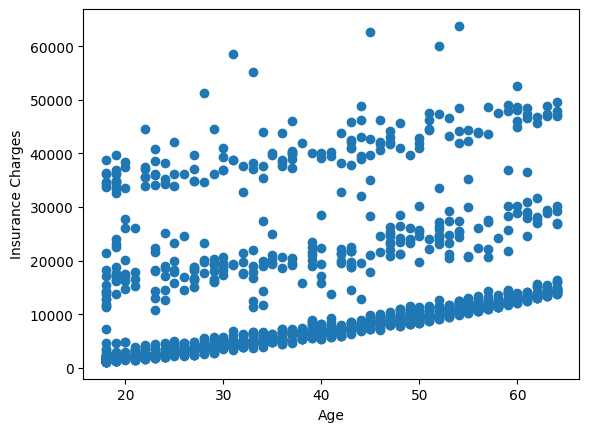

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df['age'], df['charges'])

plt.xlabel("Age")
plt.ylabel("Insurance Charges")

plt.show()

In [ ]:
X = df[['age']]
y = df['charges']
display(X.head())
display(y.head())

,age
0,19
1,18
2,28
3,33
4,32


,charges
0,16884.92400
1,1725.55230
2,4449.46200
3,21984.47061
4,3866.85520


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()


In [ ]:
model.fit(X_train, y_train)


LinearRegression()

In [ ]:
display(model.coef_)
display(model.intercept_)

array([240.59655979])

np.float64(3876.928684191691)

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

comparison.head()

,Actual,Predicted
764,9095.06825,14703.773875
887,5272.17580,12538.404837
890,29330.98315,19275.108511
1293,9301.89355,14944.370434
259,33750.29180,8448.263320


In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)

RMSE: 11661.21595205864


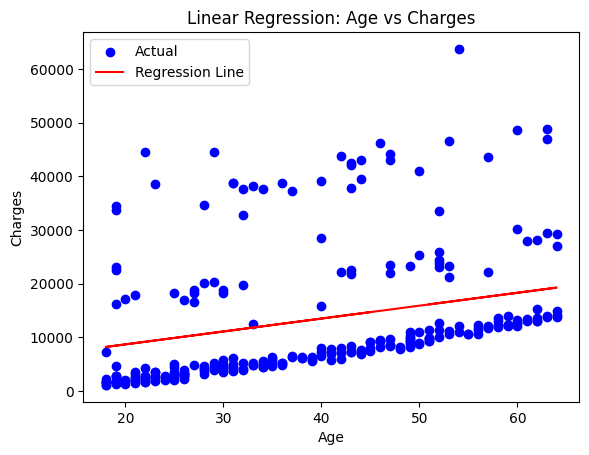

In [ ]:
plt.scatter(X_test, y_test, color="blue", label="Actual")

plt.plot(
    X_test,
    y_pred,
    color="red",
    label="Regression Line"
)

plt.xlabel("Age")
plt.ylabel("Charges")
plt.title("Linear Regression: Age vs Charges")

plt.legend()
plt.show()

In [ ]:
df_multi = pd.get_dummies(df, drop_first=True)
df_multi.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


In [ ]:
X = df_multi.drop("charges", axis=1)
y = df_multi["charges"]
X


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,False,True,False,False,True
1,18,33.770,1,True,False,False,True,False
2,28,33.000,3,True,False,False,True,False
3,33,22.705,0,True,False,True,False,False
4,32,28.880,0,True,False,True,False,False
...,...,...,...,...,...,...,...,...
1333,50,30.970,3,True,False,True,False,False
1334,18,31.920,0,False,False,False,False,False
1335,18,36.850,0,False,False,False,True,False
1336,21,25.800,0,False,False,False,False,True


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression
model_multi = LinearRegression()
model_multi.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred_multi = model_multi.predict(X_test)

In [ ]:
comparison = pd.DataFrame({
    "Actual Charges": y_test,
    "Predicted Charges": y_pred_multi
})

comparison["Error"] = (
    comparison["Actual Charges"] - comparison["Predicted Charges"]
)

comparison.head(10)

,Actual Charges,Predicted Charges,Error
764,9095.06825,8969.550274,125.517976
887,5272.17580,7068.747443,-1796.571643
890,29330.98315,36858.410912,-7527.427762
1293,9301.89355,9454.678501,-152.784951
259,33750.29180,26973.173457,6777.118343
1312,4536.25900,10864.113164,-6327.854164
899,2117.33885,170.280841,1947.058009
752,14210.53595,16903.450287,-2692.914337
1286,3732.62510,1092.430936,2640.194164
707,10264.44210,11218.343184,-953.901084


In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse_multi = np.sqrt(mean_squared_error(y_test, y_pred_multi))

print("RMSE:", rmse_multi)

RMSE: 5796.284659276273


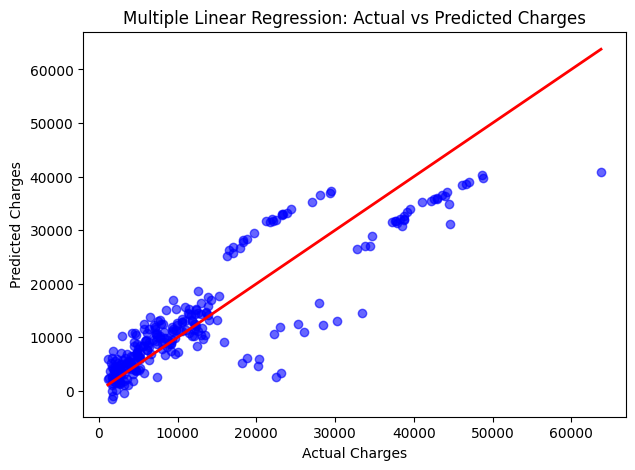

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.scatter(
    y_test,
    y_pred_multi,
    color="blue",
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2
)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Multiple Linear Regression: Actual vs Predicted Charges")

plt.show()